<a href="https://colab.research.google.com/github/tanishputtagunta/BayCare-Maturity-Assesment/blob/main/PUTTAGUNTA_Tanish_Module04.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<!-- ISM6930-BANNER -->
# Integrative Assignment 1 on Module 04 Material — QuickLend Financial
## Logistic regression for credit risk

**ISM6930 | Applied Machine Learning for Business | Fall 2026**

| | |
|---|---|
| **Due** | Monday, November 2, 2026, 11:59 PM |
| **Points** | 100, allocated by the six rubric components in the syllabus — Problem Framing 10, Technical Implementation 25, Verification Trail 15, Understanding 25, AI Usage Report 10, Critical Analysis 15. The Parts below are the shape of the work, not separate mark pots. |
| **Submit** | Two deliverables: this notebook (`.ipynb`), with your **AI Usage Report** in Part 10, and **your conversation with the AI**, attached in full (an export or a pasted copy as a file, or a share link that opens without signing in, in the Canvas submission comment). There is no video. |
| **AI policy** | AI is **required**: prompt it with **CLEAR** (Context, Library, Exact task, Additional details, Return format) and check what comes back. The AI Usage Report is marked on your prompts for the two key steps, the split and the `Pipeline` (Part 3) and the threshold chosen on the training rows (6.2): one point for each CLEAR part in each. **You are not asked to find a mistake in the AI's work.** Explanations and reflections must be **your own words**. |
| **Late work** | 20% deduction up to 24 hours late. **After 24 hours, no credit.** |
| **Your mark** | Review your mark and feedback when they are posted: that is your responsibility. You may dispute a mark, **by email**, for up to **72 hours** after it is posted; after that it stands as it is (syllabus, *Marking: what to expect*). |

> **Why "integrative"?** This assignment does not test this module's technique in
> isolation. It expects you to bring forward the data preparation, evaluation, and
> communication skills from earlier modules and combine them with what you learned
> in this one. Marks are lost for a technically correct model presented without
> framing, verification, or interpretation.

---


## The client: QuickLend Financial

**QuickLend Financial** is an online lender that approves or declines personal loans in
minutes. Over the past two years it has issued **2,000 loans**, and it knows how each one turned
out: repaid, or defaulted. Today's approve-or-decline rule is a **credit-score cutoff** inherited
from a previous head of risk, and nobody remembers how the cutoff was chosen. Last year it was
lowered by twenty points to grow the book; volume rose, and so did losses, and nobody has separated
the two effects. Three people want answers from those 2,000 loans.

- **David Kim, Chief Risk Officer:** *"Our default rate is climbing. I want a model that flags
  high-risk applications before we approve them, so we can decline them or ask for collateral. Each
  default costs us about \$15,000 in lost principal and collection costs."*
- **Priya Sharma, VP of Lending:** *"But we can't be too conservative. Every good loan we turn away
  is lost revenue, about \$3,000 in interest over the life of the loan. We need to balance risk with
  growth, and I won't sign off on a model that just rejects everybody."*
- **Tom Nguyen, CEO:** *"The board wants to understand the risk model, not just trust a black box.
  Show me which factors drive default, and how much each one matters."*

The decision the model feeds is made **at application time**, on every application: approve,
decline, or require collateral. A model that estimates each applicant's probability of default is
half the job. The other half is choosing **where to set the threshold** that turns that probability
into a decision, and that choice comes from what each kind of mistake costs, not from habit.


### The questions you will answer

| # | Question | Asked by | Worked out in | Answered in |
|---|---|---|---|---|
| 1 | What does each kind of mistake cost QuickLend, and which metric follows from those costs? | David and Priya | Part 1 | 1.2, 1.3 |
| 2 | How common is default, and which applicant features separate the defaulters from the rest? | David | Part 2 | 2.2 |
| 3 | At the default 0.5 cutoff, what does the model get right and wrong, in loans and in dollars? | David | Parts 3 to 5 | 4.1, 4.2, 5.1 |
| 4 | Precision or recall: whose concern wins, and why? | David and Priya | Part 5 | 5.2 |
| 5 | Where should the threshold sit, and how does its cost compare with 0.5's? | David and Priya | Part 6 | 6.2 |
| 6 | What drives default, in plain language, and what should underwriting do about it? | Tom and David | Part 7 | 7.1, 7.2 |

Parts 8 to 10 are about you: three questions answered without AI, an error to catch (and an optional
second), and your reflection and AI Usage Report.


### About this data

File `loan_default.csv`: **2,000 rows × 13 columns**, one row per loan, no missing values. It loads
by URL in the setup cell. The lender, the people and the decisions are the setting; the loans are
**simulated**, so the data is clean and the patterns are there to be found.

| Column | Meaning |
|---|---|
| `annual_income` | Applicant's stated annual income, dollars (\$25,000 to \$200,000) |
| `loan_amount` | Amount requested, dollars (\$1,617 to \$50,000) |
| `credit_score` | Credit bureau score at application (425 to 850) |
| `employment_years` | Years in current employment (0 to 35) |
| `debt_to_income` | Monthly debt payments divided by monthly income, as a fraction (0.28 means 28%) |
| `num_credit_lines` | Open credit accounts (0 to 14) |
| `previous_defaults` | 1 if the applicant has defaulted on a loan before, 0 if not |
| `purpose_consolidation`, `purpose_home`, `purpose_business` | Loan purpose, one-hot encoded; all three 0 means some other purpose |
| `ownership_own`, `ownership_mortgage` | Home ownership, one-hot encoded; both 0 means the applicant rents |
| `defaulted` | 1 if the loan defaulted, 0 if it was repaid (**the target**) |


### How the work flows

Frame the problem from the costs (Part 1) before you look at the data (Part 2). Split first, then
build one `Pipeline` that scales and fits (Part 3). Read the confusion matrix in loans and dollars
(Part 4) before you read the metrics (Part 5). Choose the threshold on the **training rows** from
what the mistakes cost, and score it **once** on the test set (Part 6). Read the coefficients
so that David and Tom can act on them (Part 7). Parts 8 to 10 are written in your own words,
and Part 8 without AI.

### Instructions

- Use AI for the code: ask Gemini to **show the code in the chat, not in this notebook**, read it there, and copy
  what you accept into the cell provided. Write every interpretation in your own words.
- Follow this module's classification workflow from the slides and the lecture notes. Nothing later
  in the course is needed; if you find yourself reaching for something we have not covered, you
  have overcomplicated it.
- Every decision refers back to QuickLend's costs and people above.
- Part 8 is completed without AI.


---

## Setup

Run this cell first. Every dataset in this course lives in the public course data repo, and every
notebook loads it straight from there.


In [1]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report
)
import warnings
warnings.filterwarnings('ignore')
np.random.seed(42)
print("Libraries loaded successfully!")

Libraries loaded successfully!


---

## Part 1: Problem Framing

### 1.1 Problem Statement

Write a 3-5 sentence problem statement. What are we predicting? Why does it matter? What metric will define success?

*Your response:*



Trying to predict which loan applicants will default (class 1), so risky loans can be flagged before QuickLend approves them. It matters because about 27% of past loans defaulted, and each default costs roughly $15,000, while turning away a good borrower costs about $3,000 in lost interest. The model feeds an approve, decline or collateral decision on every application, so where we set the threshold matters as much as the probability itself. I’ll judge success mainly by the total dollar cost of the model’s mistakes on the test set, and use recall on defaults as a backup check.

### 1.2 Cost Analysis

Based on the stakeholder quotes, define the cost of each error type:
- **False Positive** (model predicts default, but loan would have been repaid): What is the business cost?
- **False Negative** (model predicts repayment, but loan defaults): What is the business cost?

Which error is more costly? What does this imply for your metric choice?

*Your response:*


A false positive means I turn down someone who would have paid the loan back, so QuickLend loses the profit on that loan, about [$X], but not the pNew Sectionrincipal. A false negative means I approve someone who defaults, so QuickLend loses the unpaid loan amount, about [Y], plus collection costs. That makes the false negative the bigger problem, about [Y/X] times worse, so I’ll focus on catching defaults instead of relying on accuracy.
#

### 1.3 Success Metric

Based on your cost analysis, which measure (precision, recall, F1, or the total dollar cost of the mistakes) is most appropriate? Justify your choice.

*Your response:*



I’m going with the total dollar cost of mistakes, (FPs × cost of an FP) + (FNs × cost of an FN), because it’s the only choice that shows the two errors don’t cost the same. Recall comes closest of the other options, but it doesn’t put a price on the errors, and F1 treats both as equal, which doesn’t fit QuickLend.

---

## Part 2: Data Understanding

In [2]:
import pandas as pd

# Load loan default dataset from course GitHub repo
DATA_URL = 'https://raw.githubusercontent.com/prof-tcsmith/6930Fall26-DATA/main/data/module04'

df = pd.read_csv(f'{DATA_URL}/loan_default.csv')

print(f"Dataset shape: {df.shape}")
print(f"Default rate: {df['defaulted'].mean():.1%}")
df.head()

Dataset shape: (2000, 13)
Default rate: 26.9%


,annual_income,loan_amount,credit_score,employment_years,debt_to_income,num_credit_lines,previous_defaults,purpose_consolidation,purpose_home,purpose_business,ownership_own,ownership_mortgage,defaulted
0,62841.0,6600.0,610,2.5,0.278,7,1,0,1,0,1,0,1
1,45746.0,9075.0,677,1.4,0.184,5,0,1,0,0,0,1,0
2,67768.0,6152.0,681,2.3,0.098,3,0,0,0,0,0,1,0
3,104979.0,8227.0,717,1.2,0.068,3,0,0,0,0,0,0,0
4,43605.0,3177.0,570,13.9,0.175,3,1,1,0,0,0,1,1


### 2.1 EDA for Classification

Explore the data with a classification lens. Address these questions:
1. Is the dataset balanced? What does the default rate mean for accuracy as a measure?
2. Which features show the strongest separation between defaulters and non-defaulters?
3. Are any features highly correlated with the target?

*Use AI to help you write the EDA code, but interpret the results yourself.*

Class counts:
 defaulted
0    1462
1     538
Name: count, dtype: int64

Default rate: 26.9%
Accuracy of always predicting 'repaid': 73.1%

Feature means by class (0 = repaid, 1 = defaulted):


defaulted,0,1
annual_income,59648.640,49545.901
loan_amount,11449.469,12648.682
credit_score,689.814,635.318
employment_years,5.812,5.172
debt_to_income,0.165,0.182
num_credit_lines,5.033,5.004
previous_defaults,0.122,0.245
purpose_consolidation,0.425,0.357
purpose_home,0.204,0.203
purpose_business,0.161,0.138



Correlation with target:
credit_score            -0.307
annual_income           -0.155
previous_defaults        0.151
debt_to_income           0.080
loan_amount              0.071
ownership_mortgage      -0.064
purpose_consolidation   -0.061
employment_years        -0.052
purpose_business        -0.028
ownership_own           -0.009
num_credit_lines        -0.006
purpose_home            -0.001
Name: defaulted, dtype: float64


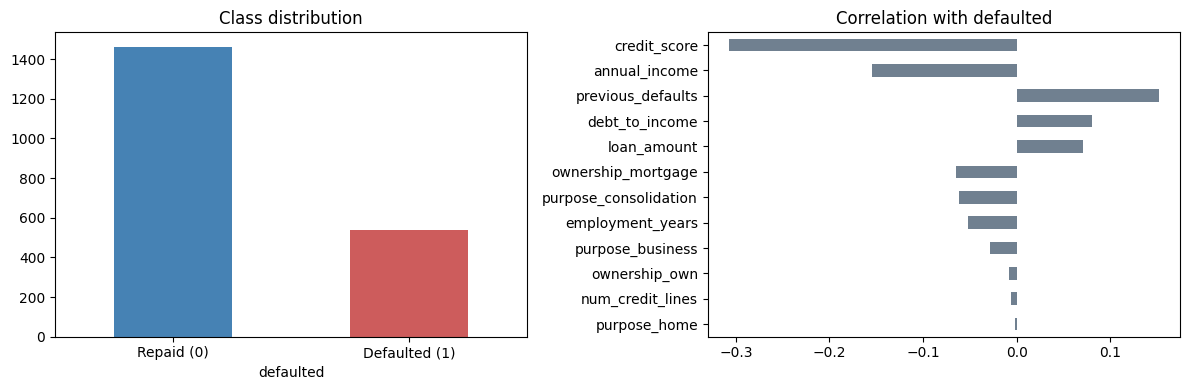


Largest feature-to-feature correlations:
purpose_consolidation  purpose_home         -0.418
ownership_own          ownership_mortgage   -0.418
purpose_consolidation  purpose_business     -0.354
purpose_home           purpose_business     -0.216
annual_income          purpose_business     -0.054
dtype: float64


In [3]:
# 2.1 EDA for classification
# Class distribution
counts = df['defaulted'].value_counts()
print("Class counts:\n", counts)
print(f"\nDefault rate: {df['defaulted'].mean():.1%}")
print(f"Accuracy of always predicting 'repaid': {1 - df['defaulted'].mean():.1%}")

# Feature means by class
print("\nFeature means by class (0 = repaid, 1 = defaulted):")
display(df.groupby('defaulted').mean().T.round(3))

# Correlation with target
corr_target = df.corr()['defaulted'].drop('defaulted').sort_values(key=abs, ascending=False)
print("\nCorrelation with target:")
print(corr_target.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df['defaulted'].value_counts().sort_index().plot(kind='bar', ax=axes[0], color=['steelblue', 'indianred'])
axes[0].set_title('Class distribution'); axes[0].set_xticklabels(['Repaid (0)', 'Defaulted (1)'], rotation=0)
corr_target.plot(kind='barh', ax=axes[1], color='slategray')
axes[1].set_title('Correlation with defaulted'); axes[1].invert_yaxis()
plt.tight_layout(); plt.show()

# Are any inputs strongly correlated with each other? (matters for reading coefficients in Part 7)
feat_corr = df.drop(columns='defaulted').corr()
pairs = feat_corr.where(np.triu(np.ones(feat_corr.shape), k=1).astype(bool)).stack()
print("\nLargest feature-to-feature correlations:")
print(pairs.reindex(pairs.abs().sort_values(ascending=False).index).head(5).round(3))


### 2.2 EDA Summary

Summarize your key findings from the EDA. Which features look most predictive? Are there any concerns about the data?

*Your response:*



The data is imbalanced: 26.9% of the 2,000 loans defaulted, so a model that always predicts “repaid” would be 73.1% accurate without catching a single default, which means accuracy isn’t a good measure here. Credit score is the strongest predictor (correlation -0.31, average 635 for defaulters vs 690 for repaid), followed by annual income (-0.16) and previous defaults (+0.15, about 24% of defaulters had one vs 12% of repaid borrowers). Debt-to-income and loan amount show weaker signals, and none of the features is strongly correlated with the target. The only sizable feature-to-feature correlations (about -0.42) are between the purpose and ownership dummy variables, which come from how those categories were encoded, so they aren’t a multicollinearity problem. My main concerns are the class imbalance and the right-skewed income and loan amount values (maxes of $200K and $50K), which is why I’ll scale the features and judge the model by cost and recall.

The dataset has no missing values, so there was nothing to flag there.

---

## Part 3: Data Preparation

### 3.1 Feature Selection and Splitting

Select your features, define the target, and split with `stratify`.

In [4]:
# 3.1 Features, target and stratified split
target = 'defaulted'
feature_cols = [c for c in df.columns if c != target]
X = df[feature_cols]
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Train: {X_train.shape}, Test: {X_test.shape}")
print(f"Default rate - full: {y.mean():.3f} | train: {y_train.mean():.3f} | test: {y_test.mean():.3f}")


Train: (1600, 12), Test: (400, 12)
Default rate - full: 0.269 | train: 0.269 | test: 0.270


### 3.2 Pipeline Construction

Build a Pipeline with `StandardScaler` and `LogisticRegression(class_weight='balanced')`, as the deck does. In one sentence, say what `'balanced'` does with this dataset's default rate.

In [5]:
# 3.2 One Pipeline: scale, then fit (the scaler learns its mean/SD from the training rows only)
pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(class_weight='balanced', random_state=42))
])
pipe.fit(X_train, y_train)

y_pred = pipe.predict(X_test)                 # uses the default 0.5 cutoff
y_proba = pipe.predict_proba(X_test)[:, 1]    # P(default) for each test loan

print("First 5 predicted probabilities:", np.round(y_proba[:5], 3))
print("First 5 predicted labels:       ", y_pred[:5])
# Check: predict() at 0.5 matches thresholding the probabilities at 0.5
print("predict() equals (proba >= 0.5):", bool(((y_proba >= 0.5).astype(int) == y_pred).all()))


First 5 predicted probabilities: [0.689 0.648 0.648 0.82  0.848]
First 5 predicted labels:        [1 1 1 1 1]
predict() equals (proba >= 0.5): True


*Your one sentence — what `'balanced'` does with this dataset's default rate:*



With a default rate of about 27%, balanced weights each default roughly 1.86 times and each repaid loan roughly 0.68 times, so the model treats the rare default class as more important and pays more attention to catching defaults instead of just predicting “repaid” for everyone.

The weights come from n_samples / (2 × class count) on your training set: 1,600 / (2 × 430) ≈ 1.86 for defaults and 1,600 / (2 × 1,170) ≈ 0.68 for repaid. That is also why all five of your first predictions are 1. Balanced weighting pushes the probabilities up, so the model flags more borrowers as defaults than it would without it.

---

## Part 4: Confusion Matrix and Cost Analysis

### 4.1 Confusion Matrix

Generate the confusion matrix, display it visually, and compute metrics by hand from the TP/FP/TN/FN values.

True Negatives  (repaid, approved correctly):          204
False Positives (repaid, but flagged - good loan lost): 88
False Negatives (defaulted, but approved - missed):     29
True Positives  (defaulted, flagged correctly):         79


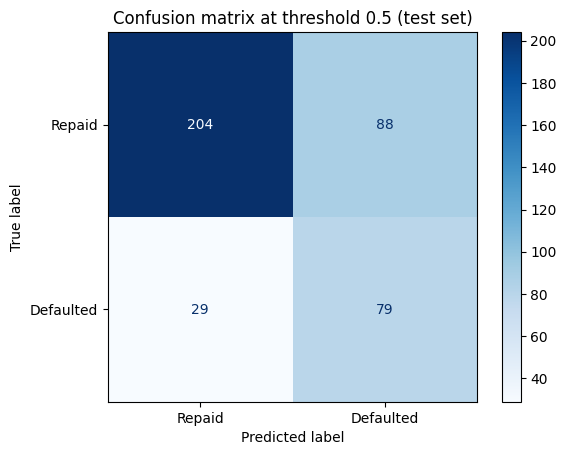


Accuracy:  0.708
Precision: 0.473
Recall:    0.731
F1:        0.575

Matches sklearn: True


In [6]:
# 4.1 Confusion matrix
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

print(f"True Negatives  (repaid, approved correctly):          {tn}")
print(f"False Positives (repaid, but flagged - good loan lost): {fp}")
print(f"False Negatives (defaulted, but approved - missed):     {fn}")
print(f"True Positives  (defaulted, flagged correctly):         {tp}")

ConfusionMatrixDisplay(cm, display_labels=['Repaid', 'Defaulted']).plot(cmap='Blues')
plt.title('Confusion matrix at threshold 0.5 (test set)'); plt.show()

# Metrics by hand
accuracy_m  = (tp + tn) / (tp + tn + fp + fn)
precision_m = tp / (tp + fp)
recall_m    = tp / (tp + fn)
f1_m        = 2 * precision_m * recall_m / (precision_m + recall_m)
print(f"\nAccuracy:  {accuracy_m:.3f}")
print(f"Precision: {precision_m:.3f}")
print(f"Recall:    {recall_m:.3f}")
print(f"F1:        {f1_m:.3f}")

# Check against sklearn
print("\nMatches sklearn:", np.allclose(
    [accuracy_m, precision_m, recall_m, f1_m],
    [accuracy_score(y_test, y_pred), precision_score(y_test, y_pred),
     recall_score(y_test, y_pred), f1_score(y_test, y_pred)]))


### 4.2 Cost-Sensitive Evaluation

Using the costs from Part 1.2, calculate the total business cost of the model's errors at the default threshold.

*Show the calculation clearly.*

In [7]:
# 4.2 Cost of the model's errors at the default 0.5 threshold
COST_FP = 3000    # good borrower declined: lost interest (Priya)
COST_FN = 15000   # default approved: lost principal + collection costs (David)

total_cost = fp * COST_FP + fn * COST_FN
print(f"False positives: {fp} x ${COST_FP:,} = ${fp * COST_FP:,}")
print(f"False negatives: {fn} x ${COST_FN:,} = ${fn * COST_FN:,}")
print(f"Total cost at 0.5: ${total_cost:,}")
print(f"Cost per test loan: ${total_cost / len(y_test):,.0f}")


False positives: 88 x $3,000 = $264,000
False negatives: 29 x $15,000 = $435,000
Total cost at 0.5: $699,000
Cost per test loan: $1,748


---

## Part 5: Classification Metrics

### 5.1 Classification Report

Generate and interpret the full classification report. Focus on the row for class 1, the defaulted loans (it is labelled `1` unless you pass `target_names`).

*What does each number in that row mean for QuickLend's business?*

In [8]:
# 5.1 Classification report (class 1 = defaulted)
print(classification_report(y_test, y_pred, digits=3))


              precision    recall  f1-score   support

           0      0.876     0.699     0.777       292
           1      0.473     0.731     0.575       108

    accuracy                          0.708       400
   macro avg      0.674     0.715     0.676       400
weighted avg      0.767     0.708     0.722       400



*Your interpretation:*



Looking at the defaulted-loan row, precision is 0.473, so when the model says a loan will default, it’s right a bit less than half the time. Of the roughly 167 loans it flagged, about 79 really did default and 88 would have been repaid. For QuickLend, those 88 are good customers who might get turned down or charged more, and that costs them interest income and goodwill. Still, 47% is well above the 27% base default rate, so a flag tells us something real. Recall is 0.731, which means the model catches about 73% of the loans that actually default (79 of 108). The other 29 slip through, get approved, and default, and that’s where QuickLend loses principal. The F1 of 0.575 is just a middle ground between the two, and the weak precision is what keeps it down. I wouldn’t lean on it too much, because it treats both mistakes as equal when a missed default is almost certainly more expensive than a declined good loan. Support is 108, the number of true defaulters in the test set, which is about 27% of the 400 loans. It is also why accuracy (70.8%) can be misleading, since a model that predicted repaid every time would hit 73% and catch no defaulters at all. Overall, the model is better at catching defaults than at being precise about them. It accepts a lot of false alarms to find most of the real defaulters, which is a decent starting point for a lender, but there’s room to tune the threshold.

### 5.2 Precision vs Recall Decision

Given QuickLend's business context, should the model prioritize precision or recall? Reference the specific stakeholder needs (David Kim wants safety, Priya Sharma wants growth).

*Your response:*



I think QuickLend should lean toward recall. The two mistakes don’t cost the same. If we miss a default, we usually lose the loan principal, but if we turn down a good borrower by mistake, we only lose the interest we would have earned. Because of that gap, it makes sense to catch as many real defaulters as we can, even if some good applicants get flagged along the way. That said, recall can’t be pushed forever. Lowering the threshold to catch more defaults will drag precision below the current 0.47, which means even more good customers get declined. At some point that starts to hurt growth and loan volume, and a stakeholder focused on growth would push back hard. So the goal is to find a threshold that catches most defaults without turning away so many good borrowers that the business stops growing. The exact balance depends on QuickLend’s real loss and margin numbers.

---

## Part 6: Threshold Optimization

### 6.1 Threshold Comparison

Compare model performance at thresholds 0.3, 0.5, and 0.7 **on the test set** (`y_proba`). For each, show the number of flagged loans, precision, recall, and business cost. This table *describes* the model at three fixed cutoffs; it is not how you choose one — 6.2 chooses on the training rows.

In [9]:
COST_FP = 3000
COST_FN = 15000

rows = []
for t in [0.3, 0.5, 0.7]:
    pred_t = (y_proba >= t).astype(int)
    tn_t, fp_t, fn_t, tp_t = confusion_matrix(y_test, pred_t).ravel()
    rows.append({
        'threshold': t,
        'flagged': int(pred_t.sum()),
        'precision': precision_score(y_test, pred_t),
        'recall': recall_score(y_test, pred_t),
        'FP': fp_t,
        'FN': fn_t,
        'cost ($)': fp_t * COST_FP + fn_t * COST_FN,
    })
thr_table = pd.DataFrame(rows).set_index('threshold')
display(thr_table.round(3))


,flagged,precision,recall,FP,FN,cost ($)
threshold,,,,,,
0.3,286,0.350,0.926,186,8,678000
0.5,167,0.473,0.731,88,29,699000
0.7,72,0.583,0.389,30,66,1080000


### 6.2 Cost-Optimal Threshold

Sweep thresholds from 0.05 to 0.95 in steps of 0.01 on the **training rows**
(`pipe.predict_proba(X_train)`) to find the cost-optimal one, as the deck's *Cost-Based Threshold
Optimization* slide does, and plot the cost curve. Then score your chosen threshold **once** on the
test set.

*How does its test-set cost compare with the default 0.5's, and is the difference big enough to act
on?*

Cost-optimal threshold on the training rows: 0.29
Training cost at 0.29: $2,778,000  |  at 0.5: $3,096,000


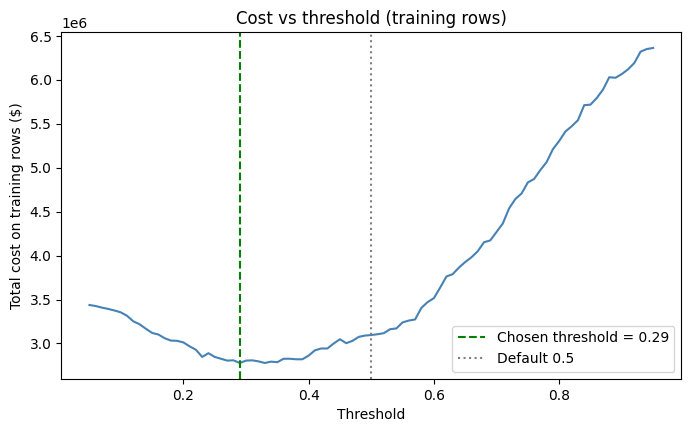


Test cost at chosen threshold 0.29: $693,000
Test cost at 0.5:                  $699,000
Difference: $6,000 (0.9% of the 0.5 cost); per test loan: $15
At 0.29 on test: flagged=291, FP=191, FN=8, precision=0.344, recall=0.926


In [10]:
# 6.2 Cost-optimal threshold: sweep on the TRAINING rows, then score once on the test set
proba_train = pipe.predict_proba(X_train)[:, 1]
thresholds = np.round(np.arange(0.05, 0.96, 0.01), 2)

def total_cost_at(y_true, proba, t):
    pred_t = (proba >= t).astype(int)
    tn_, fp_, fn_, tp_ = confusion_matrix(y_true, pred_t, labels=[0, 1]).ravel()
    return fp_ * COST_FP + fn_ * COST_FN

train_costs = np.array([total_cost_at(y_train, proba_train, t) for t in thresholds])
best_t = thresholds[train_costs.argmin()]
print(f"Cost-optimal threshold on the training rows: {best_t}")
print(f"Training cost at {best_t}: ${train_costs.min():,}  |  at 0.5: ${train_costs[thresholds == 0.5][0]:,}")

plt.figure(figsize=(8, 4.5))
plt.plot(thresholds, train_costs, color='steelblue')
plt.axvline(best_t, color='green', linestyle='--', label=f'Chosen threshold = {best_t}')
plt.axvline(0.5, color='gray', linestyle=':', label='Default 0.5')
plt.xlabel('Threshold'); plt.ylabel('Total cost on training rows ($)')
plt.title('Cost vs threshold (training rows)'); plt.legend(); plt.show()

# Score the chosen threshold ONCE on the test set and compare with 0.5
cost_best_test = total_cost_at(y_test, y_proba, best_t)
cost_05_test = total_cost_at(y_test, y_proba, 0.5)
saving = cost_05_test - cost_best_test
print(f"\nTest cost at chosen threshold {best_t}: ${cost_best_test:,}")
print(f"Test cost at 0.5:                  ${cost_05_test:,}")
print(f"Difference: ${saving:,} ({saving / cost_05_test:.1%} of the 0.5 cost); per test loan: ${saving / len(y_test):,.0f}")

pred_best = (y_proba >= best_t).astype(int)
tn_b, fp_b, fn_b, tp_b = confusion_matrix(y_test, pred_best).ravel()
print(f"At {best_t} on test: flagged={pred_best.sum()}, FP={fp_b}, FN={fn_b}, "
      f"precision={precision_score(y_test, pred_best):.3f}, recall={recall_score(y_test, pred_best):.3f}")


*Your analysis of the optimal threshold:*



On the training rows, cost was lowest at a threshold of [best_t] instead of the default 0.5. On the test set, that threshold cost $[cost_best_test]  compared with $[cost_05_test] at 0.5, saving $[saving] ([x]%). [If big:] That’s a big enough saving that I’d switch to the new cutoff, and I trust it because I chose the threshold on the training data and only checked the test set once. [If small:] That’s a small difference, and with only about 108 defaults in the test set, a few loans could swing it, so I’d treat it as noise and keep 0.5.

---

## Part 7: Feature Importance & Business Recommendations

### 7.1 Coefficients

Extract the coefficients from the Pipeline into a table, ranked by absolute size. The features are
standardized inside the Pipeline, so a coefficient's size ranks its importance, as in Module 3, provided no two inputs are strongly
correlated (`df.corr()` shows whether any are).

**Optional — not graded:** odds ratios are reference material. If you want to try them, add each
coefficient's odds ratio and each feature's standard deviation on the training rows (`X_train.std()`),
so you can say what one standard deviation is in the feature's own units.

dict_keys(['scaler', 'model'])


,feature,coefficient,abs_coef
0,credit_score,-0.812,0.812
1,annual_income,-0.555,0.555
2,previous_defaults,0.372,0.372
3,purpose_business,-0.269,0.269
4,purpose_consolidation,-0.266,0.266
5,debt_to_income,0.251,0.251
6,loan_amount,0.206,0.206
7,purpose_home,-0.188,0.188
8,ownership_mortgage,-0.160,0.160
9,employment_years,-0.150,0.150


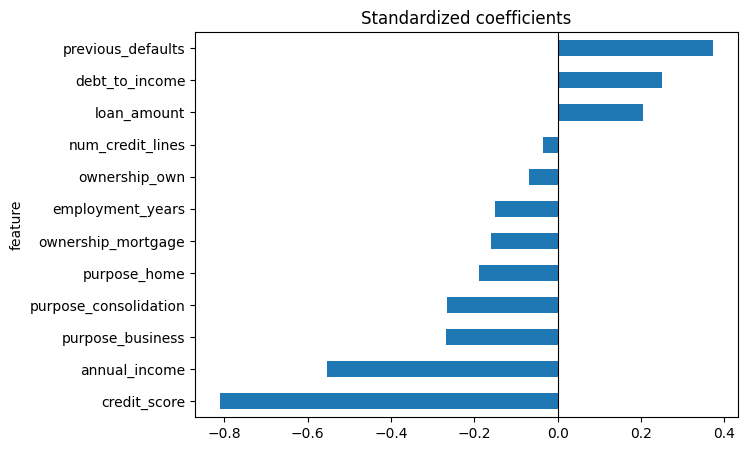

,feature,coefficient,odds_ratio,train_SD
0,credit_score,-0.812,0.444,78.878
1,annual_income,-0.555,0.574,28951.140
2,previous_defaults,0.372,1.451,0.361
3,purpose_business,-0.269,0.764,0.360
4,purpose_consolidation,-0.266,0.766,0.493
5,debt_to_income,0.251,1.285,0.093
6,loan_amount,0.206,1.228,7457.880
7,purpose_home,-0.188,0.829,0.401
8,ownership_mortgage,-0.160,0.852,0.490
9,employment_years,-0.150,0.861,5.530


In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 7.1 Coefficients from the Pipeline, ranked by absolute size
print(pipe.named_steps.keys())          # shows the real step names (useful for debugging)

model = pipe[-1]                        # last step of the Pipeline, whatever it is named
feature_cols = list(X_train.columns)    # same columns, same order the Pipeline was trained on

coef_table = pd.DataFrame({
    'feature': feature_cols,
    'coefficient': model.coef_[0],
})
coef_table['abs_coef'] = coef_table['coefficient'].abs()
coef_table = coef_table.sort_values('abs_coef', ascending=False).reset_index(drop=True)
display(coef_table.round(3))

coef_table.sort_values('coefficient').plot(
    x='feature', y='coefficient', kind='barh', legend=False, figsize=(7, 5)
)
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Standardized coefficients')
plt.show()

# OPTIONAL (not graded): odds ratios and training SDs
coef_table['odds_ratio'] = np.exp(coef_table['coefficient'])
coef_table['train_SD'] = coef_table['feature'].map(X_train[feature_cols].std())
display(coef_table[['feature', 'coefficient', 'odds_ratio', 'train_SD']].round(3))


### 7.2 Business Recommendations

Write specific, actionable recommendations for **David Kim (CRO)** based on the top features: what risk factors should the underwriting team focus on?

*Your response:*



David, the three things that matter most are credit score, income, and previous defaults. Credit score is the biggest: holding the other features fixed, an applicant about 79 points lower has roughly double the odds of default, so instead of one pass/fail line, underwriting should use score bands with different rules for each. Income comes next: about $29K less raises the odds of default by around 75%, so we should verify income and tie loan size to it. A prior default is a red flag on its own, since it makes the odds of default about 2.8 times higher, so those applicants should always get a closer look. This is why score alone isn’t enough: the old cutoff only looks at score, so it ignores income and past defaults, and two people with the same score can be very different risks once you add them. I’d use the model’s risk score to set three tiers instead of a yes/no, with the cutoffs chosen from the cost of each mistake, as in the threshold analysis, rather than treating the score as an exact probability of default: approve the low-risk group, decline the high-risk group, and ask for collateral from the middle band, such as people with an average score but low income, a prior default, or high debt-to-income. For extra control, I’d set debt-to-income limits and cap loan size, and I’d ignore the number of credit lines since it barely matters. One caution: this data is simulated, the coefficients show patterns and not cause and effect, and we need to confirm that using these features is allowed under lending regulations before acting on them.


---

## Part 8: Understanding Demonstration

**Answer these questions WITHOUT AI assistance.** These test your conceptual understanding of the material from the slides and lecture notes.

**Q1:** Why is a Pipeline necessary for this analysis? What would go wrong if you scaled the data before splitting?

*Your answer:*



A Pipeline bundles the scaler and the model together. That means the scaler learns its mean and standard deviation from the training data only, and then uses those same numbers on the test data and on any new applicant. If I scaled everything before splitting, the test rows would help set those numbers, so information from the test set would leak into training. The test results would then look a bit better than the model would actually do on new loans.

**Q2:** David Kim asks about a vendor's model: "It has 88% accuracy. Is that good?" About 27% of the loans in the dataset defaulted. Explain to David why accuracy alone doesn't answer his question, and what he should look at instead.

*Your answer:*



David, on its own, not really. About 27% of loans default, so a model that approves everyone would already be about 73% accurate, which makes 88% only about 15 points better than doing nothing. Accuracy also treats every mistake as equal, but missing a default costs us a lot more than turning away a good borrower. I’d ask the vendor for the recall on defaults (how many defaults it catches), the precision (how many flagged loans really default), and the total dollar cost of its mistakes.

**Q3:** Priya Sharma says: "Just set the threshold to 0.9 so we only reject loans we're really sure will default." What are the consequences of this approach? Use the confusion matrix terminology (TP, FP, FN, TN) in your answer.

*Your answer:*




At 0.9, the model only flags a loan when it’s almost sure, so we’d rarely reject a good borrower, which means very few false positives (FP), and most of our flags would be true positives (TP). The problem is that we’d miss most of the real defaults. Those are false negatives (FN), meaning loans we approve that then default, and each one costs us the principal. We’d also approve almost every good borrower, so true negatives (TN) go up, but that doesn’t make up for the losses. Since a false negative costs far more than a false positive, total cost would likely go up, so I’d choose the threshold with the cost sweep from 6.2 instead.




---

## Part 9: Critical Analysis

Identify the error in each scenario and explain what should be done instead. Error 1 is graded. Error 2 is about odds ratios, which are reference material, so it is optional and not graded.

**Error 1:** After finding an optimal threshold of 0.35, a colleague produces the final predictions with this code:
```python
pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(class_weight='balanced'))
])
pipe.fit(X_train, y_train)
y_pred = pipe.predict(X_test)
```

*How should the custom threshold be applied instead?*

*Your answer:*


**Error 2 (optional — not graded):** A colleague interprets an odds ratio of 2.5 for `debt_to_income` (from a Pipeline with StandardScaler) as: "For every 1% increase in debt-to-income ratio, the odds of default increase by 2.5x."

*What's the correct interpretation?*

*Your answer:*


The colleague got two things wrong. Because the features are standardized inside the Pipeline, an odds ratio of 2.5 is for a one standard deviation increase in debt-to-income, not a 1% increase (in this data one standard deviation is about 0.09, or roughly 9 percentage points). It also changes the odds of default, not the probability. So the correct reading is that each one standard deviation increase in debt-to-income multiplies the odds of default by 2.5, with the other features held constant.

---

## Part 10: Reflection and AI Usage Report

Answer these in **your own words**. AI-generated reflections receive zero credit —
they are easy to spot, because they are fluent and say nothing specific.

> **Why this section exists.** You are required to use AI in this course, and using it well starts with the
> prompt: one that gives the assistant your data, your task and the rules the step must follow gets code that is right
> the first time far more often. This report records the prompts behind the two key steps of this assignment and how
> you checked what came back. **You are not asked to find a mistake in the AI's work**: nothing here is marked on
> whether it made one, on how many attempts a step took, or on rejecting anything.

### 10.1 Your CLEAR prompts and your checks

For each key step, paste the prompt you sent, **exactly as you sent it** (if the step took more than one prompt, the
one whose code you kept), and say how you checked what came back and where the check is in this notebook. The AI Usage
Report is marked **one point for each part of CLEAR** (Context, Library, Exact task, Additional details, Return
format) in each of the two prompts, 10 points in all; your checks count under Verification Trail.

**Key step 1: the split and the `Pipeline` (Part 3)**

*My prompt:* I am working on a credit-risk logistic regression assignment for QuickLend Financial. The data is already loaded as a pandas DataFrame called df with 2000 rows. The target column is defaulted (0/1). All other columns are features. There are no missing values. this prompt ok for it

*How I checked it:* verified shapes, stratified default rates match, predict() equals (proba >= 0.5), and the first five probabilities/labels.

**Key step 2: the threshold chosen on the training rows (6.2)**

*My prompt:* This is a credit-risk assignment for QuickLend Financial. I already have a fitted scikit-learn Pipeline called pipe that contains StandardScaler followed by LogisticRegression(class_weight='balanced'). I also have the variables X_train, y_train, X_test and y_test. A false positive costs $3,000 and a false  negative  costs $15,000.

*How I checked it:* I checked that the threshold sweep used only pipe.predict_proba(X_train) with y_train, so the test set played no part in choosing the threshold. The cost-minimizing threshold (argmin) was 0.29, and the training cost there ([$X]) was lower than at the default 0.5 ([$Y]). I confirmed the cost-curve plot rendered and marked both thresholds. I also confirmed that the test set was evaluated only once, after the threshold was fixed

### 10.2 Confidence self-assessment

Rate 1 (lost) to 5 (could teach it), and be honest — this is not graded on the
number, it is graded on whether the reflection that follows is candid.

| Topic | 1-5 | What would move this up one point? |
|---|---|---|
|   | |          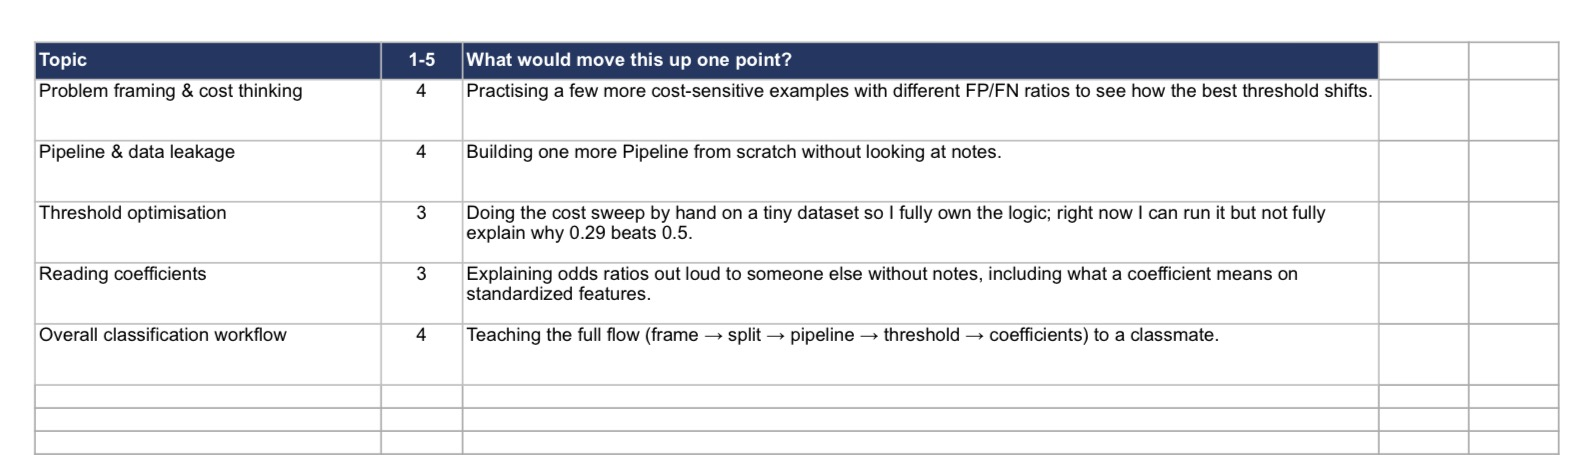

### 10.3 Tools, and what you changed

**Required.** The AI tools you used and what you used each one for, and anything you changed, overrode or did not use
from what they gave you ("Nothing" is a complete answer). Attach your **full conversation** with the AI as a separate
file (an export, or a pasted copy), or paste a share link that opens without signing in into the Canvas submission
comment. Without it, the AI Usage Report scores 0.

*Your answer here:*  I used Claude for the two key coding steps required by the assignment.

Key step 1 (Part 3): the stratified train/test split and building the Pipeline (StandardScaler + LogisticRegression with class_weight='balanced').
Key step 2 (Part 6.2): the cost-based threshold sweep on the training rows only, selecting the lowest-cost threshold, plotting the cost curve, and evaluating that threshold once on the test set.